<a href="https://colab.research.google.com/github/HashiniDivyanjanee/Hashini-Divyanjanee-HPC-Task-2638122/blob/main/Task_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!wget -q https://raw.githubusercontent.com/nothings/stb/master/stb_image.h
!wget -q https://raw.githubusercontent.com/nothings/stb/master/stb_image_write.h

In [2]:
import os, io, urllib.request
from PIL import Image

os.makedirs("images", exist_ok=True)

urls = [
    "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/starry_night.jpg",
    "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg",
    "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/messi5.jpg",
]

for i, url in enumerate(urls, start=1):
    data = urllib.request.urlopen(url).read() # Stores downloaded data in memory.
    img = Image.open(io.BytesIO(data)).convert("RGB") # It reads the image directly from memory.
    img.save(f"images/input{i}.png") # Save it as a PNG in the 'images/' folder.
    print(f"Saved images/input{i}.png ({img.size[0]}x{img.size[1]})")

Saved images/input1.png (752x600)
Saved images/input2.png (512x512)
Saved images/input3.png (548x342)


In [3]:
%%writefile sobel.cu
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <cmath>
#include <dirent.h>
#include <sys/stat.h>
#include <cuda_runtime.h>

#define STB_IMAGE_IMPLEMENTATION
#include "stb_image.h"
#define STB_IMAGE_WRITE_IMPLEMENTATION
#include "stb_image_write.h"

#define CUDA_CHECK(call)                                                     \
    do {                                                                     \
        cudaError_t err = (call);                                           \
        if (err != cudaSuccess) {                                           \
            fprintf(stderr, "CUDA error at %s:%d - %s\n", __FILE__, __LINE__, \
                    cudaGetErrorString(err));                               \
            exit(1);                                                        \
        }                                                                    \
    } while (0)

//CUDA kernel: one thread per pixel, writes Gx, Gy AND the combined magnitude
__global__ void sobelKernel(const unsigned char *in,
                             unsigned char *outGx, unsigned char *outGy, unsigned char *outMag,
                             int width, int height) {
    int x = blockIdx.x * blockDim.x + threadIdx.x;
    int y = blockIdx.y * blockDim.y + threadIdx.y;
    if (x >= width || y >= height) return;

    const int Gx[3][3] = {{-1,0,1}, {-2,0,2}, {-1,0,1}};
    const int Gy[3][3] = {{-1,-2,-1}, {0,0,0}, {1,2,1}};

    int sumX = 0, sumY = 0;
    for (int ky = -1; ky <= 1; ky++) {
        for (int kx = -1; kx <= 1; kx++) {
            int px = x + kx, py = y + ky;
            int val = 0;
            if (px >= 0 && px < width && py >= 0 && py < height) // zero padding
                val = in[py * width + px];
            sumX += val * Gx[ky + 1][kx + 1];
            sumY += val * Gy[ky + 1][kx + 1];
        }
    }

    int idx = y * width + x;

    // Gradient in X direction
    int absX = abs(sumX);
    if (absX > 255) absX = 255;
    outGx[idx] = (unsigned char)absX;

    // Gradient in Y direction
    int absY = abs(sumY);
    if (absY > 255) absY = 255;
    outGy[idx] = (unsigned char)absY;

    // Combined Sobel edge magnitude
    float mag = sqrtf((float)(sumX * sumX + sumY * sumY));
    if (mag > 255.0f) mag = 255.0f;
    outMag[idx] = (unsigned char)mag;
}

static int endsWithPng(const char *name) {
    size_t len = strlen(name);
    if (len < 4) return 0;
    return (strcmp(name + len - 4, ".png") == 0 || strcmp(name + len - 4, ".PNG") == 0);
}

int main(int argc, char *argv[]) {
    if (argc != 3) {
        printf("Usage: %s <input_folder> <output_folder>\n", argv[0]);
        return 1;
    }
    mkdir(argv[2], 0777);

    DIR *d = opendir(argv[1]);
    if (!d) { perror("Cannot open input directory"); return 1; }

    struct dirent *entry;
    int processed = 0;

    while ((entry = readdir(d)) != NULL) {
        if (!endsWithPng(entry->d_name)) continue;

        char inPath[1024];
        snprintf(inPath, sizeof(inPath), "%s/%s", argv[1], entry->d_name);

        //Step A: read image into CPU memory
        int w, h, ch;
        unsigned char *h_in = stbi_load(inPath, &w, &h, &ch, 1); // force 1-channel grayscale
        if (!h_in) { printf("Skipping unreadable file: %s\n", entry->d_name); continue; }

        size_t imgBytes = (size_t)w * h * sizeof(unsigned char);
        unsigned char *h_gx  = (unsigned char *)malloc(imgBytes);
        unsigned char *h_gy  = (unsigned char *)malloc(imgBytes);
        unsigned char *h_mag = (unsigned char *)malloc(imgBytes);

        // Step B: allocate GPU memory + copy to GPU
        unsigned char *d_in = NULL, *d_gx = NULL, *d_gy = NULL, *d_mag = NULL;
        CUDA_CHECK(cudaMalloc((void **)&d_in,  imgBytes));
        CUDA_CHECK(cudaMalloc((void **)&d_gx,  imgBytes));
        CUDA_CHECK(cudaMalloc((void **)&d_gy,  imgBytes));
        CUDA_CHECK(cudaMalloc((void **)&d_mag, imgBytes));
        CUDA_CHECK(cudaMemcpy(d_in, h_in, imgBytes, cudaMemcpyHostToDevice));

        // dynamic 2D grid, sized to this image's width/height
        dim3 threadsPerBlock(16, 16);
        dim3 numBlocks((w + threadsPerBlock.x - 1) / threadsPerBlock.x,
                        (h + threadsPerBlock.y - 1) / threadsPerBlock.y);

        //Step C: edge detection via kernel
        sobelKernel<<<numBlocks, threadsPerBlock>>>(d_in, d_gx, d_gy, d_mag, w, h);
        CUDA_CHECK(cudaGetLastError());
        CUDA_CHECK(cudaDeviceSynchronize());

        //Step D: copy results back to CPU
        CUDA_CHECK(cudaMemcpy(h_gx,  d_gx,  imgBytes, cudaMemcpyDeviceToHost));
        CUDA_CHECK(cudaMemcpy(h_gy,  d_gy,  imgBytes, cudaMemcpyDeviceToHost));
        CUDA_CHECK(cudaMemcpy(h_mag, d_mag, imgBytes, cudaMemcpyDeviceToHost));

        //Step E: write all three images to file
        char base[512];
        strncpy(base, entry->d_name, sizeof(base));
        base[sizeof(base) - 1] = '\0';
        char *dot = strrchr(base, '.');
        if (dot) *dot = '\0';

        char pathGx[1024], pathGy[1024], pathMag[1024];
        snprintf(pathGx,  sizeof(pathGx),  "%s/%s_gx.png",     argv[2], base);
        snprintf(pathGy,  sizeof(pathGy),  "%s/%s_gy.png",     argv[2], base);
        snprintf(pathMag, sizeof(pathMag), "%s/%s_edges.png",  argv[2], base);

        stbi_write_png(pathGx,  w, h, 1, h_gx,  w);
        stbi_write_png(pathGy,  w, h, 1, h_gy,  w);
        stbi_write_png(pathMag, w, h, 1, h_mag, w);

        printf("Processed %-25s (%4dx%-4d) -> %s_gx.png, %s_gy.png, %s_edges.png\n",
               entry->d_name, w, h, base, base, base);

        // Step F: free memory
        CUDA_CHECK(cudaFree(d_in));
        CUDA_CHECK(cudaFree(d_gx));
        CUDA_CHECK(cudaFree(d_gy));
        CUDA_CHECK(cudaFree(d_mag));
        stbi_image_free(h_in);
        free(h_gx);
        free(h_gy);
        free(h_mag);

        processed++;
    }
    closedir(d);

    printf("Done. %d image(s) processed (3 output files each).\n", processed);
    return 0;
}

Writing sobel.cu


In [4]:
!nvcc -O2 -o sobel sobel.cu

stb_image.h(4276): warning #550-D: variable "old_limit" was set but never used
     unsigned int cur, limit, old_limit;
                              ^

Remark: The warnings can be suppressed with "-diag-suppress <warning-number>"

stb_image.h(5185): warning #550-D: variable "idata_limit_old" was set but never used
                 stbi__uint32 idata_limit_old = idata_limit;
                              ^

stb_image.h(6972): warning #550-D: variable "out_size" was set but never used
        int out_size = 0;
            ^

stb_image.h(6973): warning #550-D: variable "delays_size" was set but never used
        int delays_size = 0;
            ^



In [5]:
!./sobel images edges_output

Processed input1.png                ( 752x600 ) -> input1_gx.png, input1_gy.png, input1_edges.png
Processed input3.png                ( 548x342 ) -> input3_gx.png, input3_gy.png, input3_edges.png
Processed input2.png                ( 512x512 ) -> input2_gx.png, input2_gy.png, input2_edges.png
Done. 3 image(s) processed (3 output files each).


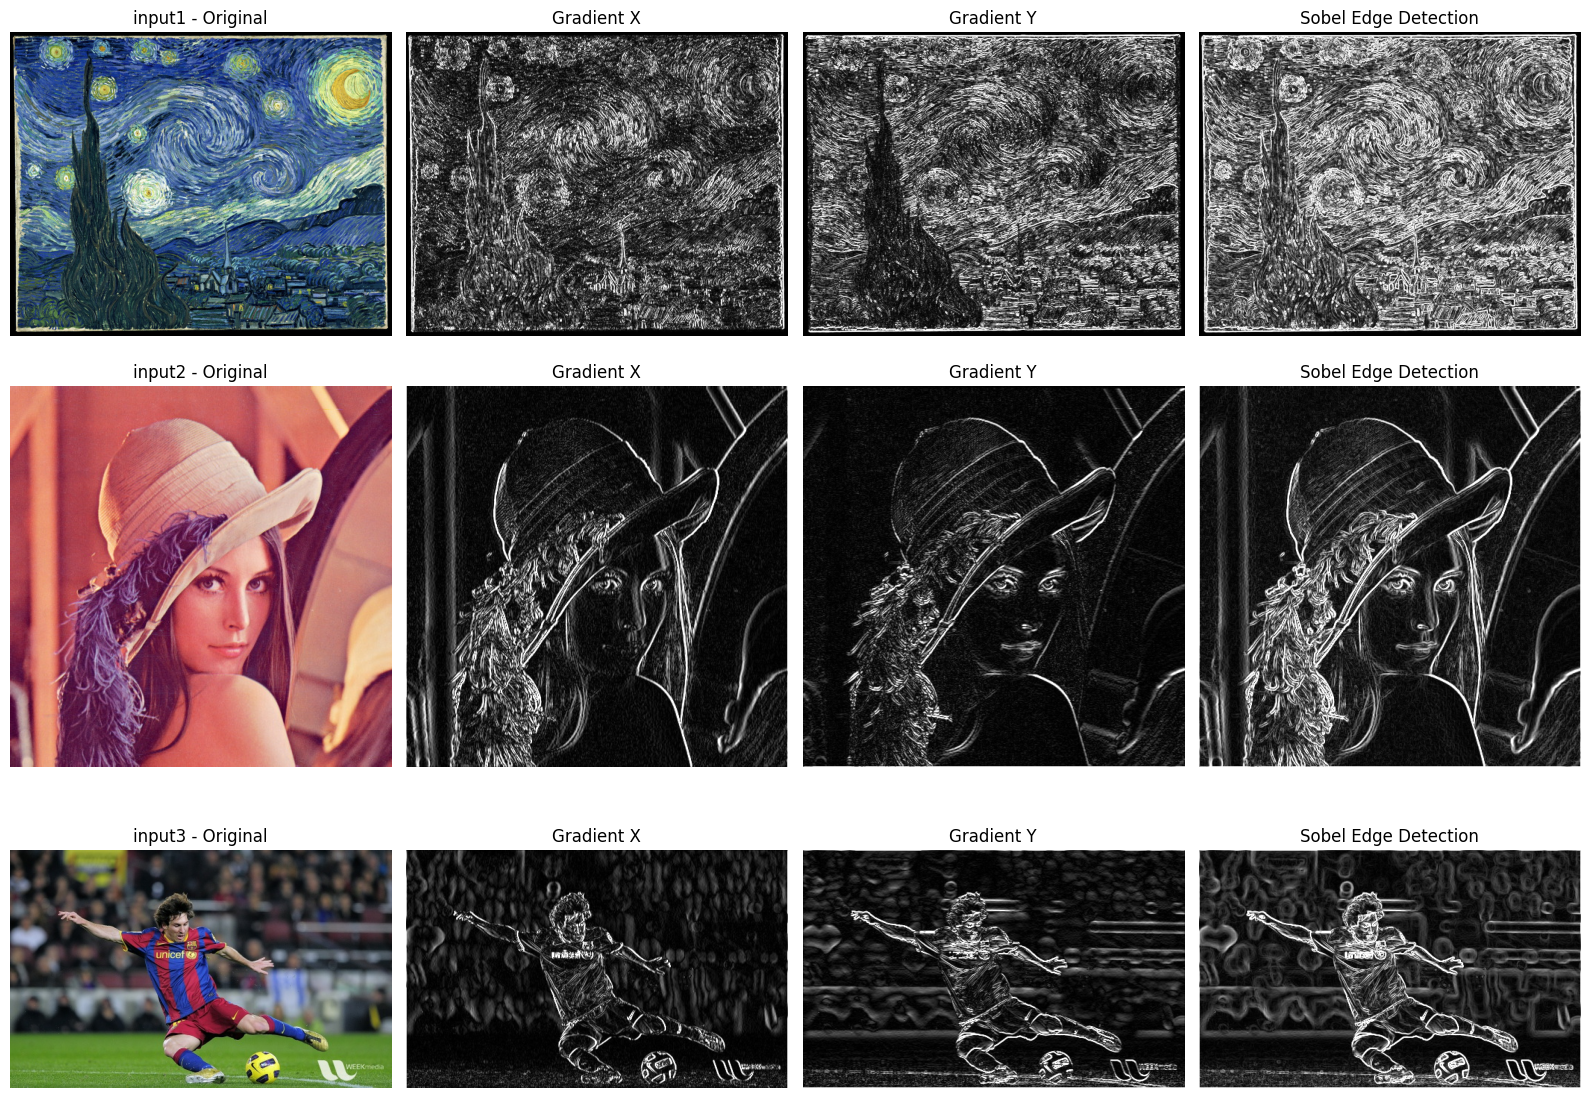

In [6]:
import matplotlib.pyplot as plt
from PIL import Image

names = ["input1", "input2", "input3"]
fig, axs = plt.subplots(len(names), 4, figsize=(16, 4*len(names)))

for row, name in enumerate(names):
    axs[row,0].imshow(Image.open(f"images/{name}.png")); axs[row,0].set_title(f"{name} - Original")
    axs[row,1].imshow(Image.open(f"edges_output/{name}_gx.png"), cmap="gray"); axs[row,1].set_title("Gradient X")
    axs[row,2].imshow(Image.open(f"edges_output/{name}_gy.png"), cmap="gray"); axs[row,2].set_title("Gradient Y")
    axs[row,3].imshow(Image.open(f"edges_output/{name}_edges.png"), cmap="gray"); axs[row,3].set_title("Sobel Edge Detection")

for ax in axs.flat: ax.axis("off")
plt.tight_layout()
plt.show()